### Bibliotecas

In [1]:
import pandas as pd
from datetime import datetime, date
from matplotlib import pyplot as plt
from scipy import stats
from patsy import dmatrices
from xgboost import XGBRegressor, XGBClassifier, plot_importance
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from math import sqrt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings("ignore")

### Importação dos Dados e Criação de Variáveis

In [2]:
dataset_dados = pd.read_excel('../data/predictions/botafogo_previsao_estadio.xlsx')

In [3]:
dataset_resultados = pd.read_excel('../data/predictions/botafogo_valores_previstos.xlsx')

In [4]:
index_novo = len(dataset_resultados)

In [5]:
dataset_dados = dataset_dados.sort_values(by='data').reset_index(drop=True)

##### Datas

In [6]:
dataset_dados['data'] = pd.to_datetime(dataset_dados['data'])

In [7]:
dataset_dados['horario'] = dataset_dados['horario'].fillna('99:99:99')

In [8]:
dataset_dados = dataset_dados.assign(dia_semana=dataset_dados['data'].dt.weekday, hora=dataset_dados['horario'].astype('str').str.slice(stop=2).astype('int').replace({99:np.nan}),
                     minuto=dataset_dados['horario'].astype('str').str.slice(start=3, stop=5).astype('int').replace({99:np.nan}))
dataset_dados['horario'] = dataset_dados['horario'].replace({'99:99:99':np.nan})

In [9]:
dataset_dados['mes'] = dataset_dados['data'].dt.month

In [10]:
dataset_dados['dia_mes'] = dataset_dados['data'].dt.day

##### Resultados de Jogos

In [11]:
dataset_dados['resultado_temporario'] = dataset_dados['gols_mandante'] - dataset_dados['gols_visitantes']

In [12]:
dataset_dados = dataset_dados.assign(resultado_partida=dataset_dados['resultado_temporario'].map(lambda x: 0 if x == 0 else 1 if x > 0 else -1))

In [13]:
dataset_dados.loc[dataset_dados[
    (dataset_dados['time_mandante'] != 'Botafogo') &
    (dataset_dados['resultado_partida'] == 1)
].index, 'resultado_partida'] = -1

In [14]:
dataset_dados.loc[dataset_dados[
    (dataset_dados['time_mandante'] != 'Botafogo') &
    (dataset_dados['resultado_partida'] == -1)
].index, 'resultado_partida'] = 1

Resultados Consecutivos

    Olhando para os últimos 5 jogos como vem sendo o "momento" do time:
        Vitória: 1 ponto
        Empate: 0 ponto
        Derrota: -1 ponto
        
    Valor Máximo: 5 pontos
    Valor Mínimo: -5 pontos

In [15]:
#RESULTADOS CONSECUTIVOS

dataset_consec = dataset_dados['resultado_partida'].shift(5, fill_value=0)

for i in range(len(dataset_dados)):
    valor = dataset_consec[i:5+i].sum()
    dataset_dados.loc[i, 'resultados_consecutivos'] = valor
    
#RESULTADO ÚLTIMO JOGO

dataset_ultimo = dataset_dados['resultado_partida'].shift(1, fill_value=0)

for i in range(len(dataset_dados)):
    valor = dataset_ultimo[i:5+i].sum()
    dataset_dados.loc[i, 'resultados_ultimo_jogo'] = valor

del dataset_consec, dataset_ultimo

##### Gols, Colocação e Time Adversário

In [16]:
dataset_dados.loc[:,['gols_botafogo','colocacao_botafogo','colocacao_adversario','time_adversario']] = dataset_dados.apply(lambda d: d[['gols_mandante','colocacao_mandante','colocacao_visitante','time_visitante']].rename(index={'gols_mandante':'gols_botafogo','colocacao_mandante':'colocacao_botafogo','colocacao_visitante':'colocacao_adversario','time_visitante':'time_adversario'})
                            if d['time_mandante'] == 'Botafogo' 
                            else d[['gols_visitantes','colocacao_visitante','colocacao_mandante','time_mandante']].rename(index={'gols_visitantes':'gols_botafogo','colocacao_visitante':'colocacao_botafogo','colocacao_mandante':'colocacao_adversario','time_mandante':'time_adversario'}), axis=1)

In [17]:
dataset_gols = dataset_dados['gols_botafogo'].shift(5, fill_value=0)
for i in range(len(dataset_dados)):
    valor = dataset_gols[i+0:5+i].sum()
    dataset_dados.loc[i, 'gols_botafogo_ultimos_jogos'] = valor
del dataset_gols

##### Percentual de Ocupacao

In [18]:
dataset_dados['percentual_ocupacao'] = round((dataset_dados['publico'] / dataset_dados['publico_max']) * 100, 2)

##### Jogos de Mando Vendido ou Compartilhado

In [19]:
dados_mando_vendido = dataset_dados[(dataset_dados['resultado_financeiro'] != dataset_dados['custo_botafogo'])]
index = dados_mando_vendido[~dados_mando_vendido['custo_botafogo'].isnull()].index

In [20]:
dataset_dados['mando_vendido_compartilhado'] = False
dataset_dados.loc[index, 'mando_vendido_compartilhado'] = True

##### Prejuízo ou Lucro

In [21]:
index = dataset_dados[dataset_dados['custo_botafogo'] <= 0].index
dataset_dados.loc[index, 'prejuizo_lucro'] = False
index = dataset_dados[dataset_dados['custo_botafogo'] > 0].index
dataset_dados.loc[index, 'prejuizo_lucro'] = True

Competições Internacionais não possuem o borderô publicado a partir de certa data, portanto vamos considerar uma regra:

    Nunca houve prejuízo em jogos com 900000 reais de arrecadação

In [22]:
index = dataset_dados[(dataset_dados['custo_botafogo'].isnull()) &
              (dataset_dados['arrecadacao'] < 900000)
             ].index
dataset_dados.loc[index, 'prejuizo_lucro'] = False
index = dataset_dados[(dataset_dados['custo_botafogo'].isnull()) &
              (dataset_dados['arrecadacao'] >= 900000)
             ].index
dataset_dados.loc[index, 'prejuizo_lucro'] = True

### Dados Usáveis para o Modelo e Tratamentos

In [23]:
dataset_dados = dataset_dados[dataset_dados['time_mandante'] == 'Botafogo']
dataset_dados = dataset_dados.reset_index(drop=True)

##### Distância dos Dias entre o Último Jogo em Casa

In [24]:
dataset_dados['data_ultimo_jogo'] = dataset_dados['data'].shift(1)

In [25]:
dataset_dados.loc[0,'data_ultimo_jogo'] = pd.to_datetime('2022-03-07')

In [26]:
dataset_dados.loc[:, 'dias_ultimo_jogo_casa'] = (dataset_dados['data'] - dataset_dados['data_ultimo_jogo']).dt.days

##### Tratamentos

In [27]:
len(dataset_dados)

162

In [28]:
dataset_dados.columns

Index(['ano_campeonato', 'campeonato', 'fase', 'estádio', 'data', 'horario',
       'temperatura', 'jogos_no_mes', 'rodada', 'tipo_partida', 'publico',
       'publico_max', 'arrecadacao', 'despesas', 'impostos',
       'resultado_financeiro', 'custo_botafogo', 'anunciou_poupar',
       'time_mandante', 'time_visitante', 'estado_adversario', 'classico',
       'eliminatorio', 'tecnico_botafogo', 'desfalques', 'colocacao_mandante',
       'colocacao_visitante', 'gols_mandante', 'gols_visitantes', 'dia_semana',
       'hora', 'minuto', 'mes', 'dia_mes', 'resultado_temporario',
       'resultado_partida', 'resultados_consecutivos',
       'resultados_ultimo_jogo', 'gols_botafogo', 'colocacao_botafogo',
       'colocacao_adversario', 'time_adversario',
       'gols_botafogo_ultimos_jogos', 'percentual_ocupacao',
       'mando_vendido_compartilhado', 'prejuizo_lucro', 'data_ultimo_jogo',
       'dias_ultimo_jogo_casa'],
      dtype='object')

In [29]:
index_coleta = dataset_dados[dataset_dados['gols_mandante'].isna()==True].index[0]

In [30]:
dataset_resultados.loc[index_novo,'ano_campeonato'] = dataset_dados['ano_campeonato'][index_coleta]
dataset_resultados.loc[index_novo,'campeonato'] = dataset_dados['campeonato'][index_coleta]
dataset_resultados.loc[index_novo,'fase'] = dataset_dados['fase'][index_coleta]
dataset_resultados.loc[index_novo,'data'] = dataset_dados['data'][index_coleta]
dataset_resultados.loc[index_novo,'time_mandante'] = dataset_dados['time_mandante'][index_coleta]
dataset_resultados.loc[index_novo,'time_visitante'] = dataset_dados['time_visitante'][index_coleta]

In [31]:
dataset_resultados

,ano_campeonato,campeonato,fase,data,time_mandante,time_visitante,previsão_ocupacao,score_modelo_1,rmse,mae,...,score_modelo_2,acurácia_modelo_2,prejuizo_lucro,previsão_resultado_partida,score_modelo_3,acurácia_modelo_3,resultado_partida,modelo_1,modelo_2,modelo_3
0,2024.0,libertadores,fase de grupos,2024-04-03,Botafogo,Junior Barranquilla,44.068220,68.200000,17.678700,14.642900,...,53.700000,0.430000,1.0,2.0,81.400000,0.640000,2.0,XGboost,XGboost,XGboost
1,2024.0,serie a,liga,2024-04-18,Botafogo,Atlético-GO,58.738190,79.900000,16.328600,14.040000,...,56.400000,0.360000,0.0,1.0,85.500000,0.570000,1.0,XGboost,XGboost,XGboost
2,2024.0,serie a,liga,2024-04-22,Botafogo,Juventude,41.466510,60.700000,20.349400,18.115000,...,53.600000,0.430000,0.0,1.0,82.100000,0.640000,1.0,XGboost,XGboost,XGboost
3,2024.0,libertadores,fase de grupos,2024-04-24,Botafogo,Universitario-PER,45.548800,72.900000,17.321600,15.208700,...,55.400000,0.330000,1.0,1.0,83.900000,0.400000,1.0,XGboost,XGboost,XGboost
4,2024.0,copa do brasil,terceira fase,2024-05-02,Botafogo,Vitória,60.616540,75.400000,19.423300,16.566600,...,71.900000,0.730000,0.0,1.0,78.900000,0.600000,1.0,XGboost,XGboost,XGboost
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,2026.0,serie a,liga,2026-05-02,Botafogo,Remo,48.006989,0.803585,16.528058,14.930667,...,0.844828,0.733333,1.0,1.0,0.560345,0.600000,0.0,XGboost,Catboost,Catboost
77,2026.0,sulamericana,fase de grupos,2026-05-06,Botafogo,Racing,47.430267,0.742785,14.479454,12.704667,...,0.786325,0.566667,0.0,1.0,0.564103,0.466667,1.0,XGboost,Catboost,XGboost
78,2026.0,serie a,liga,2026-05-17,Botafogo,Corinthians,50.305382,0.765946,13.996540,12.117333,...,0.788136,0.533333,1.0,1.0,0.559322,0.500000,1.0,XGboost,Catboost,XGboost
79,2026.0,serie a,liga,2026-07-22,Botafogo,Santos,49.038181,0.723095,18.007070,15.137000,...,0.798319,0.500000,0.0,1.0,0.546218,0.566667,1.0,XGboost,Catboost,XGboost


In [32]:
dataset_dados = dataset_dados.drop(columns=['resultado_temporario', 'gols_visitantes', 'gols_mandante',
                                           'colocacao_visitante', 'colocacao_mandante', 'time_visitante', 'time_mandante',
                                           'custo_botafogo', 'resultado_financeiro', 'impostos', 'despesas', 'arrecadacao',
                                            'publico_max', 'publico', 'gols_botafogo', 'horario', 'data_ultimo_jogo', 'tecnico_botafogo'])

In [33]:
dataset_dados.columns

Index(['ano_campeonato', 'campeonato', 'fase', 'estádio', 'data',
       'temperatura', 'jogos_no_mes', 'rodada', 'tipo_partida',
       'anunciou_poupar', 'estado_adversario', 'classico', 'eliminatorio',
       'desfalques', 'dia_semana', 'hora', 'minuto', 'mes', 'dia_mes',
       'resultado_partida', 'resultados_consecutivos',
       'resultados_ultimo_jogo', 'colocacao_botafogo', 'colocacao_adversario',
       'time_adversario', 'gols_botafogo_ultimos_jogos', 'percentual_ocupacao',
       'mando_vendido_compartilhado', 'prejuizo_lucro',
       'dias_ultimo_jogo_casa'],
      dtype='object')

In [34]:
dataset_dados.loc[dataset_dados[dataset_dados['anunciou_poupar'] == 'SIM'].index, 'anunciou_poupar'] = True
dataset_dados.loc[dataset_dados[dataset_dados['anunciou_poupar'].isnull()].index, 'anunciou_poupar'] = False
dataset_dados.loc[dataset_dados[dataset_dados['classico'] == 'SIM'].index, 'classico'] = True
dataset_dados.loc[dataset_dados[dataset_dados['classico'].isnull()].index, 'classico'] = False
dataset_dados.loc[dataset_dados[dataset_dados['eliminatorio'] == 'SIM'].index, 'eliminatorio'] = True
dataset_dados.loc[dataset_dados[dataset_dados['eliminatorio'].isnull()].index, 'eliminatorio'] = False

In [35]:
len(dataset_dados.columns)

30

In [36]:
dataset_dados = pd.get_dummies(dataset_dados, columns=['campeonato', 'estádio', 'tipo_partida', 'estado_adversario', 'time_adversario', 'fase'])

In [37]:
dataset_dados = dataset_dados.astype({'anunciou_poupar': bool,
                                      'classico': bool,
                                      'eliminatorio': bool,
                                       'prejuizo_lucro': bool
                                     })

In [38]:
dataset_previsao = dataset_dados[dataset_dados['data'] >= pd.to_datetime(date.today())]
dataset_dados = dataset_dados[dataset_dados['data'] < pd.to_datetime(date.today())]
dataset_dados = dataset_dados.drop(columns=['data'])
dataset_previsao = dataset_previsao.drop(columns=['data'])
dataset_dados = dataset_dados.reset_index(drop=True)

In [39]:
len(dataset_dados)

150

##### Normalizações com Substituição por IQR e Box-Cox

In [40]:
listaColunas = ['ano_campeonato', 'temperatura', 'jogos_no_mes', 'rodada', 'desfalques', 'dia_semana', 'hora', 'mes', 'dia_mes', 'colocacao_botafogo',
                'colocacao_adversario', 'gols_botafogo_ultimos_jogos', 'dias_ultimo_jogo_casa']

In [41]:
for i in listaColunas:
    
    if stats.shapiro(dataset_dados[i])[1] < 0.05:
    
        quartilUm = np.percentile(dataset_dados[i], 25)
        quartilTres = np.percentile(dataset_dados[i], 75)
        iqr = (quartilTres - quartilUm) * 1.5
        lim_superior = quartilTres + iqr
        lim_inferior = quartilUm - iqr
        
        dataset_dados.loc[dataset_dados[dataset_dados[i] > lim_superior].index, i] = lim_superior
        dataset_dados.loc[dataset_dados[dataset_dados[i] < lim_inferior].index, i] = lim_inferior
    
        if stats.shapiro(dataset_dados[i])[1] < 0.05:

            dataset_dados.loc[dataset_dados[dataset_dados[i] <= 0].index, i] = 0.0000001
            dataset_dados[i] = stats.boxcox(dataset_dados[i])[0]

##### Min Max Scaler

In [42]:
for i in listaColunas:
    scaler = MinMaxScaler()
    dataset_dados[i] = scaler.fit_transform(dataset_dados[[i]])

In [43]:
dataset_dados.to_csv('../data/processed/dados_modelo_final.csv', index=False)

### Datasets Modelos

Haverão Três Modelos, cada um olhando para uma variável alvo específica, as variáveis alvo serão:

    - percentual_ocupacao: Olhando para tentarmos prever a quantidade de pessoas que irão aos jogos
    - prejuizo_lucro: Olhando para tentarmos prever se o jogo foi rentável (olhando apenas para o contexto do jogo)
    - resultado_partida: Olhando para tentarmos prever o resultado do jogo (Derrota, Vitória ou Empate
    
Sendo assim cada modelo terá seu dataset específico, pois as variáveis alvo não são passíveis de serem utilizadas nos modelos que não sejam os seus por não serem valores disponíveis para a previsão antes do evento acontecer, chamaremos essas varíaveis de indisponíveis.

In [44]:
dados_modelo_percentual_ocupacao = dataset_dados.drop(columns=['prejuizo_lucro', 'resultado_partida']).copy()
dados_modelo_prejuizo_lucro = dataset_dados.drop(columns=['percentual_ocupacao', 'resultado_partida']).copy()
dados_modelo_resultado_partida = dataset_dados.drop(columns=['percentual_ocupacao', 'prejuizo_lucro']).copy()

### Análise Exploratória

##### Funções Úteis

In [45]:
def concentracao_valores (dados, coluna):
    if len(dados[coluna].unique()) > 3:        
        print(dados[coluna].describe())
    else:        
        print(dados[coluna].value_counts())

In [46]:
def correlacao_modelos (dados, coluna):
    print('Menores Valores')
    print('----------------------')
    print(dados.corr()[coluna].sort_values().head(7))
    print('======================')
    print('Maiores Valores')
    print('----------------------')
    print(dados.corr()[coluna].sort_values(ascending=False).head(7))

In [47]:
def visualizacoes (dados, coluna, label):
    if len(dados[coluna].unique()) > 3: 
        fig, ax = plt.subplots()
        ax.hist(dados[coluna])
        ax.set_xlabel(label)
        ax.set_title('Análise Visual - Histograma - '+label)
        plt.show()

In [48]:
def taxas_erro (valores_reais, valores_previstos):
    #RMSE
    rmse = sqrt(mean_squared_error(valores_reais, valores_previstos))
    print('Erro médio quadrático: ', rmse)
    #MAE
    mae = mean_absolute_error(valores_reais, valores_previstos)
    print('Erro médio absoluto: ', mae)
    return rmse, mae

Esse artigo me ajudou com a tunagem dos hiperparâmetros:

    - https://www.analyticsvidhya.com/blog/2016/03/complete-guide-parameter-tuning-xgboost-with-codes-python/

In [49]:
def tunning_hiperpametros_xgboost (modelo, X_train, y_train):

    parametros = list()
    
    print('Testando Variáveis: max_depth, min_child_weight')
    
    param_test = {
     'max_depth':range(3,10,2),
     'min_child_weight':range(1,6,2),
    }
    
    gsearch = GridSearchCV(estimator = modelo(
                    learning_rate=0.01, max_depth=5, n_estimators=200, n_jobs=-1, random_state=1, seed=42,
                    min_child_weight=1, gamma = 0, subsample = 0.8, colsample_bytree = 0.8, scale_pos_weight = 1
                   ), 
                    param_grid = param_test, scoring='roc_auc', n_jobs=-1, cv=10)      
    gsearch.fit(X_train, y_train)
        
    max_depth = gsearch.best_params_['max_depth']
    min_child_weight = gsearch.best_params_['min_child_weight']
    parametros.append(max_depth)
    parametros.append(min_child_weight)
    
    print('Melhores valores: ', gsearch.best_params_)
    
    print('-----------------------------')  
    
    print('Testando Variáveis:gamma')
    
    param_test = {
     'gamma':[i/10.0 for i in range(0,5)],
    }
    
    gsearch = GridSearchCV(estimator = modelo(
                    learning_rate=0.01, max_depth=max_depth, n_estimators=200, n_jobs=-1, random_state=1, seed=42,
                    min_child_weight=min_child_weight, gamma = 0 , subsample = 0.8, colsample_bytree = 0.8, scale_pos_weight = 1
                   ), 
                    param_grid = param_test, scoring='roc_auc', n_jobs=-1, cv=10)      
    gsearch.fit(X_train, y_train)
    
    print('Melhores valores: ', gsearch.best_params_)
    gamma = gsearch.best_params_['gamma']
    parametros.append(gamma)
    
    print('-----------------------------')  
    
    print('Testando Variáveis: subsample, colsample_bytree')
    
    param_test = {
     'subsample':[i/10.0 for i in range(6,10)],
     'colsample_bytree':[i/10.0 for i in range(6,10)]
    }
    
    gsearch = GridSearchCV(estimator = modelo(
                    learning_rate=0.01, max_depth=max_depth, n_estimators=200, n_jobs=-1, random_state=1, seed=42,
                    min_child_weight=min_child_weight, gamma = gamma, subsample = 0.8, colsample_bytree = 0.8, scale_pos_weight = 1
                   ), 
                    param_grid = param_test, scoring='roc_auc', n_jobs=-1, cv=10)      
    gsearch.fit(X_train, y_train)
    
    print('Melhores valores: ', gsearch.best_params_)
    parametros.append(gsearch.best_params_['subsample'])
    parametros.append(gsearch.best_params_['colsample_bytree'])
    
    print('-----------------------------')  
    
    print('Testando Variáveis: reg_alpha')
    
    param_test = {
     'reg_alpha':[1e-5, 1e-2, 0.1, 1, 100]
    }
    
    gsearch = GridSearchCV(estimator = modelo(
                    learning_rate=0.01, max_depth=max_depth, n_estimators=200, n_jobs=-1, random_state=1, seed=42,
                    min_child_weight=min_child_weight, gamma = gamma, subsample = gsearch.best_params_['subsample'],
                    colsample_bytree = gsearch.best_params_['colsample_bytree'], scale_pos_weight = 1
                   ), 
                    param_grid = param_test, scoring='roc_auc', n_jobs=-1, cv=10)      
    gsearch.fit(X_train, y_train)
    
    print('Melhores valores: ', gsearch.best_params_)
    parametros.append(gsearch.best_params_['reg_alpha'])
    
    print('-----------------------------')  

    return parametros

In [50]:
def tunning_hiperpametros_catboost(modelo, X_train, y_train):


    parametros = list()
    def grid_search(param_grid, estimator, X_train, y_train):
        gsearch = GridSearchCV(estimator=estimator, param_grid=param_grid, 
                               scoring='roc_auc', n_jobs=-1, cv=10)
        gsearch.fit(X_train, y_train)
        return gsearch.best_params_

    modelo_base = modelo(learning_rate=0.01, random_state=1, verbose=False)

    print('Testando Variáveis: depth, min_data_in_leaf')
    param_test = {
        'depth': [3, 5, 7, 9],
        'min_data_in_leaf': [1, 5, 10]
    }
    best_params_depth = grid_search(param_test, modelo_base, X_train, y_train)
    parametros.append(best_params_depth['depth'])
    parametros.append(best_params_depth['min_data_in_leaf'])
    print('Melhores valores para depth e min_data_in_leaf: ', best_params_depth)
    

    print('Testando Variáveis: learning_rate, iterations')
    param_test = {
        'learning_rate': [0.01, 0.05, 0.1],
        'iterations': [100, 200, 300]
    }
    modelo_base.depth = best_params_depth['depth']
    modelo_base.min_data_in_leaf = best_params_depth['min_data_in_leaf']
    best_params_lr_iter = grid_search(param_test, modelo_base, X_train, y_train)
    parametros.append(best_params_lr_iter['iterations'])
    parametros.append(best_params_lr_iter['learning_rate'])
    print('Melhores valores para learning_rate e iterations: ', best_params_lr_iter)

    print('Testando Variáveis: subsample, colsample_bylevel')
    param_test = {
        'subsample': [i/10.0 for i in range(6,10)],
        'colsample_bylevel': [i/10.0 for i in range(6,10)]
    }
    modelo_base.learning_rate = best_params_lr_iter['learning_rate']
    modelo_base.iterations = best_params_lr_iter['iterations']
    best_params_subsample = grid_search(param_test, modelo_base, X_train, y_train)
    parametros.append(best_params_subsample['subsample'])
    print('Melhores valores para subsample e colsample_bylevel: ', best_params_subsample)

    print('-----------------------------')

    return parametros

##### Modelo 1

In [51]:
concentracao_valores(dados_modelo_percentual_ocupacao, 'percentual_ocupacao')

count    150.000000
mean      44.119933
std       24.262078
min        5.190000
25%       23.967500
50%       41.375000
75%       64.867500
max       91.780000
Name: percentual_ocupacao, dtype: float64


In [52]:
correlacao_modelos(dados_modelo_percentual_ocupacao, 'percentual_ocupacao')

Menores Valores
----------------------
campeonato_carioca              -0.531572
estado_adversario_RJ            -0.354445
anunciou_poupar                 -0.350997
temperatura                     -0.271251
mando_vendido_compartilhado     -0.245329
time_adversario_Portuguesa-RJ   -0.243393
time_adversario_Bangu           -0.217341
Name: percentual_ocupacao, dtype: float64
Maiores Valores
----------------------
percentual_ocupacao        1.000000
mes                        0.503880
campeonato_libertadores    0.327901
campeonato_serie a         0.231664
rodada                     0.216316
tipo_partida_ida           0.168450
estado_adversario_URU      0.160824
Name: percentual_ocupacao, dtype: float64


In [53]:
dados_modelo_percentual_ocupacao.corr()['percentual_ocupacao']

ano_campeonato                     NaN
temperatura                  -0.271251
jogos_no_mes                 -0.123296
rodada                        0.216316
anunciou_poupar              -0.350997
                                ...   
fase_segunda fase            -0.021596
fase_semi-final               0.051199
fase_semi-final - taça rio   -0.206064
fase_terceira fase           -0.000506
fase_unico                   -0.099435
Name: percentual_ocupacao, Length: 138, dtype: float64

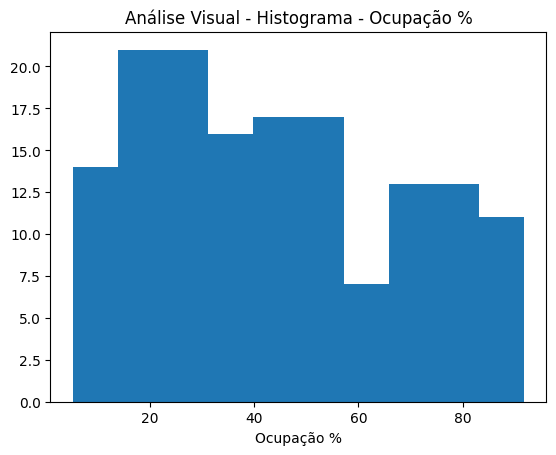

In [54]:
visualizacoes(dados_modelo_percentual_ocupacao, 'percentual_ocupacao', 'Ocupação %')

##### Modelo 2 

In [55]:
concentracao_valores(dados_modelo_prejuizo_lucro, 'prejuizo_lucro')

prejuizo_lucro
False    75
True     75
Name: count, dtype: int64


In [56]:
correlacao_modelos(dados_modelo_prejuizo_lucro, 'prejuizo_lucro')

Menores Valores
----------------------
campeonato_carioca      -0.354509
anunciou_poupar         -0.329700
estado_adversario_RJ    -0.221139
temperatura             -0.217143
eliminatorio            -0.195283
time_adversario_Bangu   -0.185695
fase_segunda fase       -0.165521
Name: prejuizo_lucro, dtype: float64
Maiores Valores
----------------------
prejuizo_lucro             1.000000
mes                        0.355667
rodada                     0.322937
campeonato_serie a         0.268608
campeonato_libertadores    0.229175
tipo_partida_liga          0.209215
estado_adversario_CE       0.204124
Name: prejuizo_lucro, dtype: float64


##### Modelo 3

In [57]:
concentracao_valores(dados_modelo_resultado_partida, 'resultado_partida')

resultado_partida
 1    83
-1    35
 0    32
Name: count, dtype: int64


In [58]:
correlacao_modelos(dados_modelo_resultado_partida, 'resultado_partida')

Menores Valores
----------------------
time_adversario_Flamengo      -0.307024
classico                      -0.222858
fase_final                    -0.185501
estado_adversario_MT          -0.170396
time_adversario_Cuiabá-MT     -0.170396
temperatura                   -0.150112
mando_vendido_compartilhado   -0.143781
Name: resultado_partida, dtype: float64
Maiores Valores
----------------------
resultado_partida                1.000000
resultados_ultimo_jogo           0.501328
dia_mes                          0.200690
gols_botafogo_ultimos_jogos      0.179599
time_adversario_RB Bragantino    0.167799
jogos_no_mes                     0.164043
time_adversario_Bangu            0.152650
Name: resultado_partida, dtype: float64


### Modelagem

#### Modelo 1

In [59]:
dados_modelo_percentual_ocupacao

,ano_campeonato,temperatura,jogos_no_mes,rodada,anunciou_poupar,classico,eliminatorio,desfalques,dia_semana,hora,...,fase_final - taça rio,fase_liga,fase_oitavas-de-final,fase_quartas-de-final,fase_quinta fase,fase_segunda fase,fase_semi-final,fase_semi-final - taça rio,fase_terceira fase,fase_unico
0,0.0,0.529412,0.386406,0.000000,False,True,True,0.555556,0.000000,0.784529,...,False,False,False,False,False,False,True,False,False,False
1,0.0,0.647059,0.000000,0.000000,False,False,False,0.277778,1.000000,0.198270,...,False,True,False,False,False,False,False,False,False,False
2,0.0,0.705882,0.000000,0.339683,False,False,False,0.388889,1.000000,0.000000,...,False,True,False,False,False,False,False,False,False,False
3,0.0,0.352941,0.386406,0.164064,False,False,True,0.444444,0.702412,1.000000,...,False,False,False,False,False,False,False,False,True,False
4,0.0,0.411765,0.612700,0.448092,False,False,False,0.277778,1.000000,0.442139,...,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,0.0,0.411765,1.000000,0.265341,False,False,False,0.111111,0.401262,0.599594,...,False,False,False,False,False,False,False,False,False,False
146,0.0,0.294118,0.000000,0.689057,False,False,False,0.111111,0.911274,0.198270,...,False,True,False,False,False,False,False,False,False,False
147,0.0,0.235294,0.386406,0.339683,False,False,False,0.222222,0.571282,1.000000,...,False,False,False,False,False,False,False,False,False,False
148,0.0,0.588235,0.612700,0.728894,False,False,False,0.277778,1.000000,0.198270,...,False,True,False,False,False,False,False,False,False,False


In [60]:
cutoff = int(len(dados_modelo_percentual_ocupacao) * 0.8)

train = dados_modelo_percentual_ocupacao.iloc[:cutoff].copy()
test = dados_modelo_percentual_ocupacao.iloc[cutoff:].copy()

X_train = train.drop(columns=['percentual_ocupacao'])
y_train = train['percentual_ocupacao']

X_test = test.drop(columns=['percentual_ocupacao'])
y_test = test['percentual_ocupacao']

eval_set = [(X_test, y_test)]

##### Xgboost

In [61]:
parametros = tunning_hiperpametros_xgboost(XGBRegressor, X_train, y_train)

Testando Variáveis: max_depth, min_child_weight
Melhores valores:  {'max_depth': 3, 'min_child_weight': 1}
-----------------------------
Testando Variáveis:gamma
Melhores valores:  {'gamma': 0.0}
-----------------------------
Testando Variáveis: subsample, colsample_bytree
Melhores valores:  {'colsample_bytree': 0.6, 'subsample': 0.6}
-----------------------------
Testando Variáveis: reg_alpha
Melhores valores:  {'reg_alpha': 1e-05}
-----------------------------


In [62]:
model_xgboost = XGBRegressor(verbosity=0, learning_rate=0.01, max_depth=parametros[0], n_estimators=10000, n_jobs=-1, random_state=1,
                    min_child_weight=parametros[1], gamma = parametros[2], subsample = parametros[3], colsample_bytree = parametros[4], 
                    scale_pos_weight = 1, reg_alpha= parametros[5], early_stopping_rounds=10, eval_metric='rmse')
model_xgboost.fit(X_train, y_train, eval_set=eval_set, verbose = 1)

[0]	validation_0-rmse:23.18753
[1]	validation_0-rmse:23.11333
[2]	validation_0-rmse:23.05642
[3]	validation_0-rmse:22.99405
[4]	validation_0-rmse:22.89038
[5]	validation_0-rmse:22.84897
[6]	validation_0-rmse:22.87329
[7]	validation_0-rmse:22.81145
[8]	validation_0-rmse:22.70322
[9]	validation_0-rmse:22.65120
[10]	validation_0-rmse:22.63718
[11]	validation_0-rmse:22.58354
[12]	validation_0-rmse:22.52523
[13]	validation_0-rmse:22.45510
[14]	validation_0-rmse:22.44769
[15]	validation_0-rmse:22.40654
[16]	validation_0-rmse:22.31564
[17]	validation_0-rmse:22.28704
[18]	validation_0-rmse:22.24080
[19]	validation_0-rmse:22.18979
[20]	validation_0-rmse:22.18605
[21]	validation_0-rmse:22.07462
[22]	validation_0-rmse:22.11936
[23]	validation_0-rmse:22.09144
[24]	validation_0-rmse:22.04055
[25]	validation_0-rmse:22.02622
[26]	validation_0-rmse:21.98139
[27]	validation_0-rmse:21.95865
[28]	validation_0-rmse:21.86211
[29]	validation_0-rmse:21.84920
[30]	validation_0-rmse:21.79806
[31]	validation_0-

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.6, device=None, early_stopping_rounds=10,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=0.0, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.01, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=1, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=10000,
             n_jobs=-1, num_parallel_tree=None, ...)

In [63]:
model_xgboost.feature_importances_

array([0.        , 0.01379315, 0.01027208, 0.01583906, 0.02338866,
       0.01167201, 0.00122462, 0.01952562, 0.01124013, 0.01861809,
       0.00738552, 0.04834145, 0.01479838, 0.01033131, 0.0146571 ,
       0.03919753, 0.01224356, 0.01730233, 0.01619953, 0.01479786,
       0.01780827, 0.08124768, 0.0216423 , 0.0254716 , 0.02236408,
       0.01052232, 0.02627535, 0.0068502 , 0.00063828, 0.        ,
       0.00634671, 0.01539632, 0.00092406, 0.        , 0.00469094,
       0.        , 0.        , 0.01269213, 0.        , 0.0104992 ,
       0.        , 0.01235168, 0.01095985, 0.00659103, 0.        ,
       0.00548718, 0.        , 0.        , 0.03163802, 0.        ,
       0.01117911, 0.01600981, 0.        , 0.        , 0.0006879 ,
       0.        , 0.        , 0.        , 0.03916905, 0.01075541,
       0.        , 0.01139839, 0.        , 0.        , 0.        ,
       0.00977115, 0.01063637, 0.00996727, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

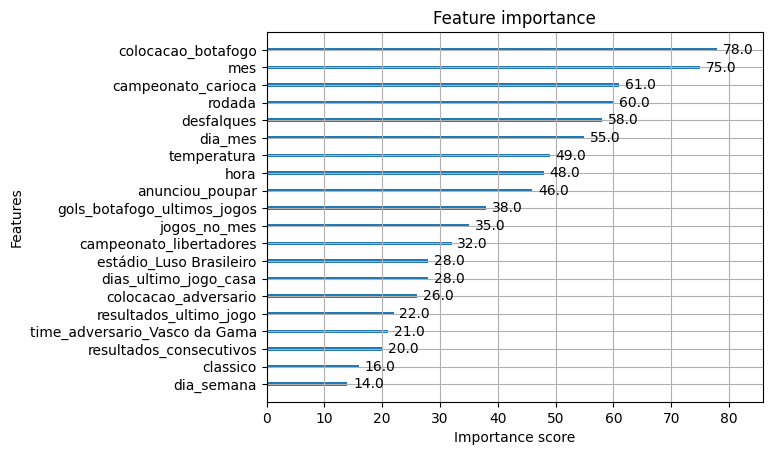

In [64]:
plot_importance(model_xgboost, max_num_features=20)

In [65]:
score = model_xgboost.score(X_train, y_train)  
score

0.6477558206507334

##### Catboost

In [66]:
parametros = tunning_hiperpametros_catboost(CatBoostRegressor, X_train, y_train)

Testando Variáveis: depth, min_data_in_leaf
Melhores valores para depth e min_data_in_leaf:  {'depth': 3, 'min_data_in_leaf': 1}
Testando Variáveis: learning_rate, iterations
Melhores valores para learning_rate e iterations:  {'iterations': 100, 'learning_rate': 0.01}
Testando Variáveis: subsample, colsample_bylevel
Melhores valores para subsample e colsample_bylevel:  {'colsample_bylevel': 0.6, 'subsample': 0.6}
-----------------------------


In [67]:
parametros

[3, 1, 100, 0.01, 0.6]

In [68]:
model_catboost = CatBoostRegressor(learning_rate=parametros[3], depth=parametros[0], min_data_in_leaf=parametros[1], iterations=parametros[2], random_state=1,  
                     subsample = parametros[4], colsample_bylevel=parametros[4], verbose=False)

model_catboost.fit(X_train, y_train, eval_set=eval_set, use_best_model=True, early_stopping_rounds=10)

CatBoostRegressor(colsample_bylevel=0.6, depth=3, iterations=100, learning_rate=0.01, loss_function='RMSE', min_data_in_leaf=1, random_state=1, subsample=0.6, verbose=False)

In [69]:
model_catboost.feature_importances_

array([0.00000000e+00, 1.35556676e+00, 0.00000000e+00, 4.48916715e+00,
       5.74032293e+00, 1.70114588e-01, 0.00000000e+00, 1.61120373e+00,
       7.66933566e-02, 7.61008889e-01, 3.55018831e-02, 2.62923790e+01,
       6.19762926e-01, 4.50707694e-01, 3.64359090e-01, 1.51639611e+01,
       3.24229710e-01, 1.22546312e+00, 4.95840823e-01, 3.12322580e-01,
       3.19140485e-02, 3.19502133e+01, 2.77528918e-01, 4.06746249e+00,
       3.98902496e-02, 1.62638635e-05, 5.70433973e-01, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 1.40101984e-01, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 5.72405087e-02, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.38814044e-01,
       0.00000000e+00, 1.82926407e-01, 5.12062642e-02, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 4.14305616e-02,
       1.92742232e-01, 0.00000000e+00, 1.12344146e-02, 4.52074953e-02,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

Text(0.5, 1.0, 'Feature Importance')

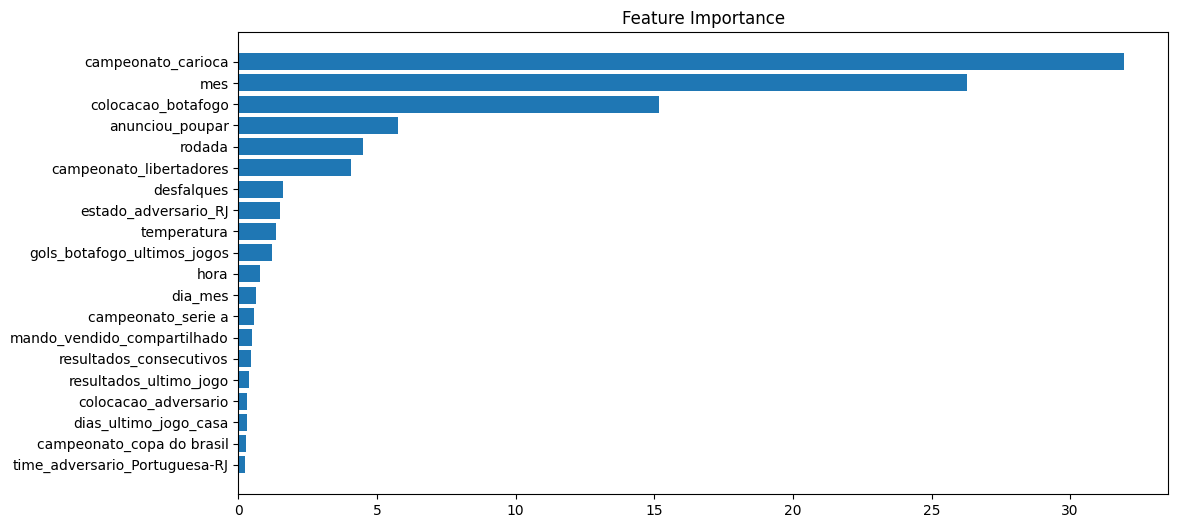

In [70]:
feature_importance = model_catboost.feature_importances_
sorted_idx = np.argsort(feature_importance)
fig = plt.figure(figsize=(12, 6))
plt.barh(range(20), feature_importance[sorted_idx][-20:], align='center')
plt.yticks(range(20), np.array(X_test.columns)[sorted_idx][-20:])
plt.title('Feature Importance')

In [71]:
score = model_catboost.score(X_train, y_train)  
score

np.float64(0.35310373117374316)

##### Decisao de qual modelo será

In [72]:
if model_catboost.score(X_train, y_train) > model_xgboost.score(X_train, y_train) :
    model = model_catboost
    modelo_escolhido = 'Catboost'
    dataset_resultados.loc[index_novo,'score_modelo_1'] = model_catboost.score(X_train, y_train)
else:
    model = model_xgboost
    modelo_escolhido = 'XGboost'
    dataset_resultados.loc[index_novo,'score_modelo_1'] = model_xgboost.score(X_train, y_train)

dataset_resultados.loc[index_novo,'modelo_1'] = modelo_escolhido
modelo_escolhido

'XGboost'

In [73]:
y_pred = model.predict(X_test)
predictions = [round(value, 2) for value in y_pred]
len(predictions)

30

Text(0.5, 1.0, 'Previsão Ocupação')

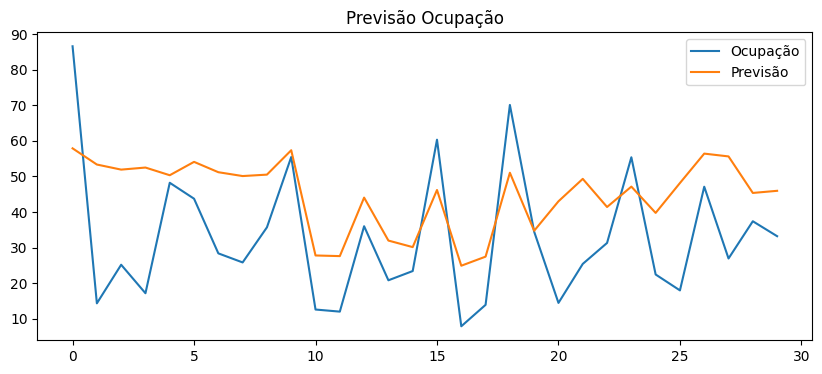

In [74]:
y_test = y_test.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(y_test, label='Ocupação')
ax.plot(predictions, label='Previsão')
ax.legend()
ax.set_title("Previsão Ocupação")

In [75]:
rmse, mae = taxas_erro(y_test, predictions)
dataset_resultados.loc[index_novo,'rmse'] = rmse
dataset_resultados.loc[index_novo,'mae'] = mae

Erro médio quadrático:  19.50216847666842
Erro médio absoluto:  16.800999969482422


##### Previsões

In [76]:
dataset_previsao_modelo = dataset_previsao.drop(columns=['percentual_ocupacao', 'prejuizo_lucro', 'resultado_partida']
                                               ).copy().reset_index(drop=True).loc[:0]

In [77]:
model.predict(dataset_previsao_modelo)
dataset_resultados.loc[index_novo,'previsão_ocupacao'] = model.predict(dataset_previsao_modelo)[0]

#### Modelo 2

In [78]:
dados_modelo_prejuizo_lucro = dados_modelo_prejuizo_lucro[~dados_modelo_prejuizo_lucro['prejuizo_lucro'].isna() == True].reset_index(drop=True)

In [79]:
train = dados_modelo_prejuizo_lucro.iloc[:cutoff].copy()
test = dados_modelo_prejuizo_lucro.iloc[cutoff:].copy()

X_train = train.drop(columns=['percentual_ocupacao'])
y_train = train['percentual_ocupacao']

X_test = test.drop(columns=['percentual_ocupacao'])
y_test = test['percentual_ocupacao']

eval_set = [(X_test, y_test)]

KeyError: "['percentual_ocupacao'] not found in axis"

##### XGBoost

In [ ]:
parametros = tunning_hiperpametros_xgboost(XGBClassifier, X_train, y_train)

In [ ]:
model_xgboost = XGBClassifier(verbosity=0, learning_rate=0.01, max_depth=parametros[0], n_estimators=10000, n_jobs=-1, random_state=1,
                    min_child_weight=parametros[1], gamma = parametros[2], subsample = parametros[3], colsample_bytree = parametros[4], 
                    scale_pos_weight = 1, reg_alpha= parametros[5], early_stopping_rounds=10, eval_metric='auc')

model_xgboost.fit(X_train, y_train, eval_set=eval_set, verbose = 1)

In [ ]:
model_xgboost.feature_importances_

In [ ]:
plot_importance(model_xgboost, max_num_features=20)

In [ ]:
score = model_xgboost.score(X_train, y_train)  
score

##### Catboost

In [ ]:
parametros = tunning_hiperpametros_catboost(CatBoostRegressor, X_train, y_train)

In [ ]:
model_catboost = CatBoostClassifier(learning_rate=parametros[3], depth=parametros[0], min_data_in_leaf=parametros[1], iterations=parametros[2], random_state=1,  
                     subsample = parametros[4], colsample_bylevel=parametros[4], verbose=False, bootstrap_type='Bernoulli')

model_catboost.fit(X_train, y_train, eval_set=eval_set, use_best_model=True, early_stopping_rounds=10)

In [ ]:
model_catboost.feature_importances_

In [ ]:
feature_importance = model_catboost.feature_importances_
sorted_idx = np.argsort(feature_importance)
fig = plt.figure(figsize=(12, 6))
plt.barh(range(20), feature_importance[sorted_idx][-20:], align='center')
plt.yticks(range(20), np.array(X_test.columns)[sorted_idx][-20:])
plt.title('Feature Importance')

In [ ]:
score = model_catboost.score(X_train, y_train)  
score

##### Decisao de qual modelo será

In [ ]:
if model_catboost.score(X_train, y_train) > model_xgboost.score(X_train, y_train) :
    model = model_catboost
    modelo_escolhido = 'Catboost'
    dataset_resultados.loc[index_novo,'score_modelo_2'] = model_catboost.score(X_train, y_train)
else:
    model = model_xgboost
    modelo_escolhido = 'XGboost'
    dataset_resultados.loc[index_novo,'score_modelo_2'] = model_xgboost.score(X_train, y_train)
dataset_resultados.loc[index_novo,'modelo_2'] = modelo_escolhido
modelo_escolhido

In [ ]:
y_pred = model.predict(X_test)
if modelo_escolhido == 'Catboost':
    predictions = [int(value) for value in y_pred]
else:
    predictions = [round(value, 2) for value in y_pred]
len(predictions)

In [ ]:
sns.heatmap(confusion_matrix(y_test, predictions), 
            annot=True,
            fmt='g')
plt.ylabel('Acontecido',fontsize=13)
plt.xlabel('Previsão',fontsize=13)
plt.show()

In [ ]:
print(classification_report(y_test, predictions))

In [ ]:
acc = accuracy_score(y_test, predictions)
dataset_resultados.loc[index_novo,'acurácia_modelo_2'] = acc

##### Previsões

In [ ]:
model.predict(dataset_previsao_modelo)
if model.predict(dataset_previsao_modelo)[0] == True:
    dataset_resultados.loc[index_novo,'previsão_prejuizo_lucro'] = 1
else:
    dataset_resultados.loc[index_novo,'previsão_prejuizo_lucro'] = 0

#### Modelo 3

In [ ]:
train = dados_modelo_resultado_partida.iloc[:cutoff].copy()
test = dados_modelo_resultado_partida.iloc[cutoff:].copy()

X_train = train.drop(columns=['percentual_ocupacao'])
y_train = train['percentual_ocupacao']
y_train.loc[y_train[y_train['resultado_partida'] == -1].index, 'resultado_partida'] = 2
y_train['resultado_partida'] = y_train['resultado_partida'].astype(int)

X_test = test.drop(columns=['percentual_ocupacao'])
y_test = test['percentual_ocupacao']
y_test.loc[y_test[y_test['resultado_partida'] == -1].index, 'resultado_partida'] = 2
y_test['resultado_partida'] = y_test['resultado_partida'].astype(int)

eval_set = [(X_test, y_test)]

##### XGboost

In [ ]:
parametros = tunning_hiperpametros_xgboost(XGBClassifier, X_train, y_train)

In [ ]:
model_xgboost = XGBClassifier(verbosity=0, learning_rate=0.01, max_depth=parametros[0], n_estimators=10000, n_jobs=-1, random_state=1,
                    min_child_weight=parametros[1], gamma = parametros[2], subsample = parametros[3], colsample_bytree = parametros[4], 
                    scale_pos_weight = 1, reg_alpha= parametros[5], early_stopping_rounds=10, eval_metric='auc')

model_xgboost.fit(X_train, y_train, eval_set=eval_set, verbose = 1)

In [ ]:
model_xgboost.feature_importances_

In [ ]:
plot_importance(model_xgboost, max_num_features=20)

In [ ]:
score = model_xgboost.score(X_train, y_train)  
score

##### Catboost

In [ ]:
parametros = tunning_hiperpametros_catboost(CatBoostRegressor, X_train, y_train)

In [ ]:
model_catboost = CatBoostClassifier(learning_rate=parametros[3], depth=parametros[0], min_data_in_leaf=parametros[1], iterations=parametros[2], random_state=1,  
                     subsample = parametros[4], colsample_bylevel=parametros[4], verbose=False, bootstrap_type='Bernoulli')

model_catboost.fit(X_train, y_train, eval_set=eval_set, use_best_model=True, early_stopping_rounds=10)

In [ ]:
model_catboost.feature_importances_

In [ ]:
feature_importance = model_catboost.feature_importances_
sorted_idx = np.argsort(feature_importance)
fig = plt.figure(figsize=(12, 6))
plt.barh(range(20), feature_importance[sorted_idx][-20:], align='center')
plt.yticks(range(20), np.array(X_test.columns)[sorted_idx][-20:])
plt.title('Feature Importance')

In [ ]:
score = model_catboost.score(X_train, y_train)  
score

##### Decisao de qual modelo será

In [ ]:
if model_catboost.score(X_train, y_train) > model_xgboost.score(X_train, y_train) :
    model = model_catboost
    modelo_escolhido = 'Catboost'
    dataset_resultados.loc[index_novo,'score_modelo_3'] = model_catboost.score(X_train, y_train)
else:
    model = model_xgboost
    modelo_escolhido = 'XGboost'
    dataset_resultados.loc[index_novo,'score_modelo_3'] = model_xgboost.score(X_train, y_train)

dataset_resultados.loc[index_novo,'modelo_3'] = modelo_escolhido
modelo_escolhido

In [ ]:
y_pred = model.predict(X_test)
if modelo_escolhido == 'Catboost':
    predictions = [int(value) for value in y_pred]
else:
    predictions = [round(value, 2) for value in y_pred]
len(predictions)

In [ ]:
sns.heatmap(confusion_matrix(y_test, predictions), 
            annot=True,
            fmt='g')
plt.ylabel('Acontecido',fontsize=13)
plt.xlabel('Previsão',fontsize=13)
plt.show()

In [ ]:
print(classification_report(y_test, predictions))
acc = accuracy_score(y_test, predictions)
dataset_resultados.loc[index_novo,'acurácia_modelo_3'] = acc

##### Previsões

In [ ]:
model.predict(dataset_previsao_modelo)
dataset_resultados.loc[index_novo,'previsão_resultado_partida'] = model.predict(dataset_previsao_modelo)[0]

In [ ]:
dataset_resultados.to_excel('../data/predictions/botafogo_valores_previstos.xlsx', index=False)